# 🪰 Может ли муха искать товары?

**Uzum Fly** использует обонятельный контур из коннектома FlyWire v783 для поиска среди 24 252 товаров исторического каталога. Товары и сессии синтетических персон превращаются в запахи. Лайки меняют веса по упрощённому правилу, вдохновлённому дофаминовой пластичностью; дофаминовые нейроны не симулируются.

Этот ноутбук пересчитывает графики из артефактов `data/fly/`. Текстовые эмбеддинги можно восстановить из закоммиченного каталога командой `PYTHONPATH=. .venv/bin/python scripts/rebuild_embeddings_from_catalog.py`. Результат зависит от версии публичного чекпойнта и библиотек. Модель не обучена на действиях пользователей Uzum.


In [1]:
import json, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from flyrec import DATA, connectome, mushroom, retrieval as R
from flyrec.odor import OdorEncoder, antennal_lobe

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
C = {'real': '#6f9e2e', 'fly': '#8b6fd6', 'base': '#b0784f', 'ref': '#8a94a6'}

ev = json.loads((DATA / 'eval_results.json').read_text())
rows = pd.DataFrame(ev['rows'])
rows['mapping'] = np.where(rows.mapping.isin(['strength', '-']), 'по силе гломерулы', 'вразнобой')
summary = rows.groupby(['variant', 'mapping'])[['map', 'recall100', 'leaf_p20', 'l2_p20']].agg(['mean', 'std'])

## Главный график: поиск похожих товаров по клеткам Кеньона

Задача из статьи [Dasgupta, Stevens, Navlakha (Science, 2017)](https://www.science.org/doi/10.1126/science.aam9868).
Для 1 000 случайных товаров нужно найти их 100 ближайших соседей по исходному текстовому эмбеддингу
(384 измерения). Муха знает только, какие 234 из 4 678 клеток Кеньона загорелись. Метрика — mAP
(1,0 = идеальное совпадение со списком точных соседей). Все варианты получают одинаковый вход
и одинаковое торможение APL; отличается только проводка.

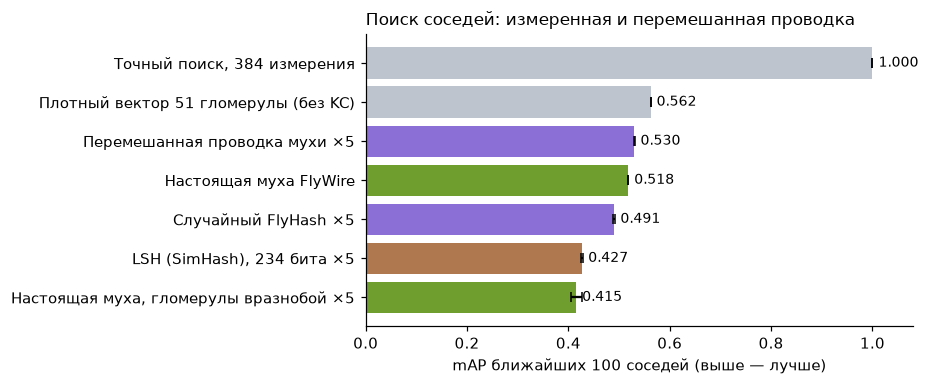

In [2]:
order = [
    ('dense_384', 'по силе гломерулы', 'Точный поиск, 384 измерения', 'ref'),
    ('dense_pn51', 'по силе гломерулы', 'Плотный вектор 51 гломерулы (без KC)', 'ref'),
    ('shuffled', 'по силе гломерулы', 'Перемешанная проводка мухи ×5', 'fly'),
    ('flywire', 'по силе гломерулы', 'Настоящая муха FlyWire', 'real'),
    ('random_flyhash', 'по силе гломерулы', 'Случайный FlyHash ×5', 'fly'),
    ('simhash_pn51', 'по силе гломерулы', 'LSH (SimHash), 234 бита ×5', 'base'),
    ('flywire', 'вразнобой', 'Настоящая муха, гломерулы вразнобой ×5', 'real'),
]
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for y, (v, m, name, kind) in enumerate(order):
    mu, sd = summary.loc[(v, m), ('map', 'mean')], summary.loc[(v, m), ('map', 'std')]
    ax.barh(y, mu, color=C[kind], xerr=0 if np.isnan(sd) else sd, capsize=3, alpha=.55 if kind == 'ref' else 1)
    ax.text(mu + .012, y, f'{mu:.3f}', va='center', fontsize=9)
ax.set_yticks(range(len(order)), [o[2] for o in order]); ax.invert_yaxis()
ax.set_xlim(0, 1.08); ax.set_xlabel('mAP ближайших 100 соседей (выше — лучше)')
ax.set_title('Поиск соседей: измеренная и перемешанная проводка', loc='left', fontsize=11)
plt.tight_layout(); plt.show()

### TL;DR

| Вопрос | Ответ | Результат |
|---|---|---|
| Ищет ли разреженный KC-код похожие товары? | Да, в прокси-задаче сохранения соседей исходного текстового эмбеддинга | mAP 0,518 |
| Помогают ли измеренные синапсы FlyWire? | В этом тесте преимущества нет: контроль сохраняет степени нейронов и веса каждой KC | 0,518 против 0,530 у перемешанной проводки |
| Лучше ли настоящая муха случайного FlyHash? | Только при назначении главных признаков наиболее связанным гломерулам | 0,518 против 0,491; при случайной раскладке 0,415 |
| Можно ли заключить, что муха лучше LSH? | Пока нет: размеры кода и цена поиска различаются | 4 678 бит KC против 234 бит SimHash |
| Сколько стоит запрос? | На этом каталоге индекс строится на CPU за ~1,4 с, запрос сессии за ~15 мс | см. таблицу ниже |
| Что дала полная спайковая модель? | При испытанных стимулах активность KC слишком широка; причина без дополнительных контролей неизвестна | около 70% KC |
| Может ли модель реагировать на лайк? | Да, после лайка меняется MBON-валентность и полка; до лайков ранжирует KC-overlap | синтетический сценарий, раздел 6 |

**Вывод для RecSys:** реализация вычисляет поиск по нейронной схеме, но качество рекомендаций не измерено. Нужны реальные сессии, сравнение при равном бюджете и добавочный recall к существующим источникам.


In [3]:
tldr = summary.round(3)
tldr.index = [f'{v} · {m}' for v, m in tldr.index]
tldr.columns = [f'{a} {b}' for a, b in tldr.columns]
print('Скорость:', ev['timing'], '| каталог:', ev['catalog_size'], 'товаров | запросов:', ev['n_queries'])
tldr

Скорость: {'index_build_s': 1.41, 'session_query_ms': 14.96} | каталог: 24252 товаров | запросов: 1000


,map mean,map std,recall100 mean,recall100 std,leaf_p20 mean,leaf_p20 std,l2_p20 mean,l2_p20 std
dense_384 · по силе гломерулы,1.000,NaN,1.000,NaN,0.329,NaN,0.701,NaN
dense_pn51 · по силе гломерулы,0.562,NaN,0.639,NaN,0.303,NaN,0.656,NaN
flywire · вразнобой,0.415,0.011,0.512,0.010,0.273,0.003,0.600,0.003
flywire · по силе гломерулы,0.518,NaN,0.604,NaN,0.279,NaN,0.634,NaN
random_flyhash · вразнобой,0.490,0.002,0.580,0.002,0.289,0.001,0.632,0.002
random_flyhash · по силе гломерулы,0.491,0.002,0.580,0.002,0.290,0.002,0.633,0.002
shuffled · вразнобой,0.437,0.010,0.533,0.009,0.278,0.002,0.611,0.003
shuffled · по силе гломерулы,0.530,0.001,0.614,0.001,0.283,0.002,0.639,0.001
simhash_pn51 · по силе гломерулы,0.427,0.003,0.528,0.003,0.271,0.002,0.607,0.004


## 1. Нос мухи: что мы взяли из коннектома

У дрозофилы запах проходит три станции:

1. **ORN** — рецепторные нейроны на антенне. Около 50 типов; все нейроны одного типа сходятся в одну **гломерулу**.
2. **PN** — проекционные нейроны. Каждая гломерула передаёт сигнал своими PN; латеральное торможение нормирует общий уровень.
3. **Клетки Кеньона (KC)** в грибовидном теле. Каждая слушает несколько случайных-на-вид гломерул. Тормозной нейрон **APL** оставляет активными ~5% KC — получается разреженный «отпечаток» запаха.

Дальше KC передают сигнал на **MBON** — выходные нейроны «подойти» и «уйти». Дофаминовые нейроны (DAN) меняют силу синапсов KC → MBON — так муха учится.

`flyrec/connectome.py` берёт из FlyWire v783 синапсы PN → KC (порог ≥ 5 синапсов на ребро) и агрегирует их по гломерулам.

гломерул: 51, клеток Кеньона с PN-входом: 4678, синапсов PN→KC: 297,727
ORN→PN внутри своей гломерулы: 99.1% (санити-чек разметки)


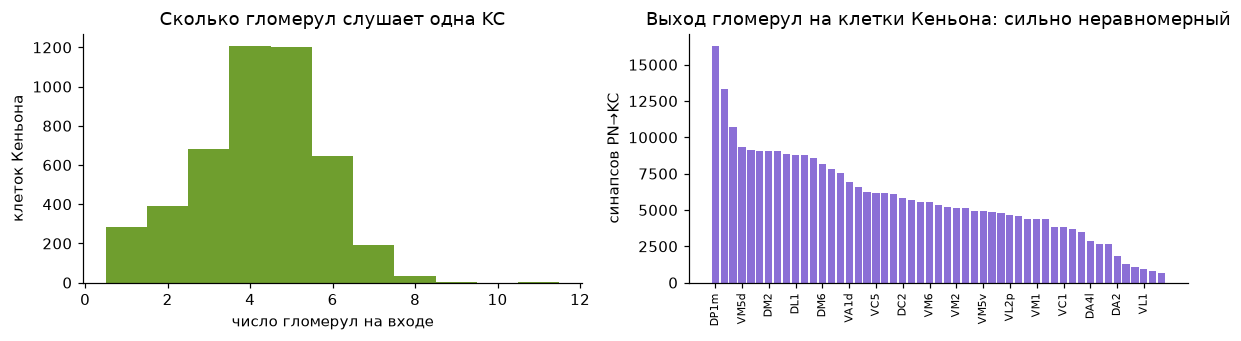

In [4]:
c = connectome.load()
W = c['W']
print(f"гломерул: {len(c['glomeruli'])}, клеток Кеньона с PN-входом: {W.shape[1]}, синапсов PN→KC: {int(W.sum()):,}")
print(f"ORN→PN внутри своей гломерулы: {float(c['orn_pn_same_glomerulus']):.1%} (санити-чек разметки)")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
indeg = (W > 0).sum(0)
axs[0].hist(indeg, bins=np.arange(0.5, indeg.max() + 1.5), color=C['real'])
axs[0].set(title='Сколько гломерул слушает одна KC', xlabel='число гломерул на входе', ylabel='клеток Кеньона')
out = pd.Series(W.sum(1), index=c['glomeruli']).sort_values(ascending=False)
axs[1].bar(range(len(out)), out.values, color=C['fly'])
axs[1].set_xticks(range(0, len(out), 3), out.index[::3], rotation=90, fontsize=7)
axs[1].set(title='Выход гломерул на клетки Кеньона: сильно неравномерный', ylabel='синапсов PN→KC')
plt.tight_layout(); plt.show()

Неравномерность справа важна для всей истории. Одни гломерулы (например, **DA1** — феромон cVA, или **DC3**)
говорят с тысячами KC, другие почти молчат. Настоящая муха «слышит» некоторые запахи громче.
Это единственное, чем её проводка отличается от случайной, и дальше мы проверим, помогает ли это товарам.

## 2. Товар → запах

Товар превращается в текст «название | категория | подкатегория» и кодируется мультиязычной моделью
`paraphrase-multilingual-MiniLM-L12-v2` (384 числа). У мухи всего 51 канал, поэтому берём 51 главную
компоненту каталога. Самая «объёмная» компонента идёт в гломерулу с самым сильным выходом на KC.
Это **наш модельный выбор**, а не биология, и в разделе 5 он будет проверен.

Дальше, как у мухи: `softplus` → частота ORN ≥ 0 → нормализация Olsen et al. (2010) → центрирование (латеральное торможение).

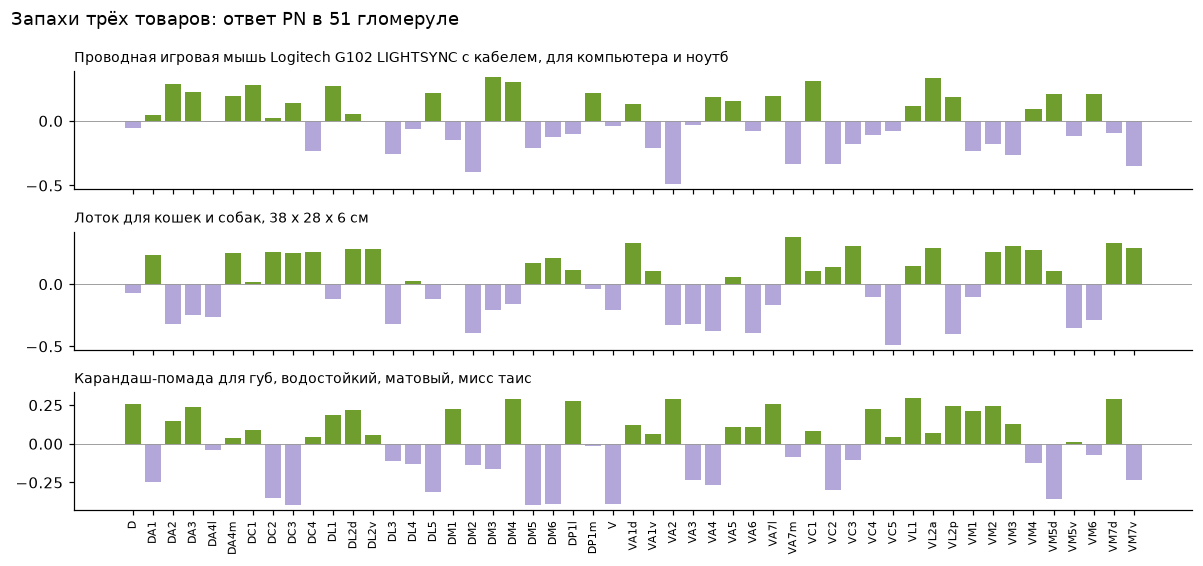

In [5]:
catalog = json.loads((ROOT / 'data/catalog.json').read_text())
titles = np.array([p['title'] for p in catalog]); leaf = np.array([p['leaf'] for p in catalog]); l2 = np.array([p['category'] for p in catalog])
emb = np.load(DATA / 'item_emb.npy').astype(np.float32)
enc = OdorEncoder.fit(emb, W.sum(1))
orn = enc.orn(emb); pn = antennal_lobe(orn)
find = lambda s: int(np.flatnonzero(np.char.find(np.char.lower(titles.astype(str)), s.lower()) >= 0)[0])
examples = [find('игровая мышь'), find('лоток для кошек'), find('помада')]
fig, axs = plt.subplots(len(examples), 1, figsize=(11, 5.2), sharex=True)
for ax, i in zip(axs, examples):
    ax.bar(range(len(c['glomeruli'])), pn[i], color=np.where(pn[i] > 0, C['real'], '#b3a6d9'))
    ax.axhline(0, color='#999', lw=.6); ax.set_title(titles[i][:80], loc='left', fontsize=9)
axs[-1].set_xticks(range(len(c['glomeruli'])), c['glomeruli'], rotation=90, fontsize=7)
fig.suptitle('Запахи трёх товаров: ответ PN в 51 гломеруле', x=.01, ha='left'); plt.tight_layout(); plt.show()

## 3. Клетки Кеньона: разреженный отпечаток

Каждая KC суммирует свои PN с весами-синапсами FlyWire. APL оставляет 5% самых возбуждённых: 234 из 4 678.
Без подстройки KC с 1–2 входами «горят» на четверти каталога, и код вырождается. Поэтому добавлен
**гомеостаз** (Apostolopoulou & Lin, 2020): каждая KC нормирует свою возбудимость. Он одинаков у всех вариантов проводки.

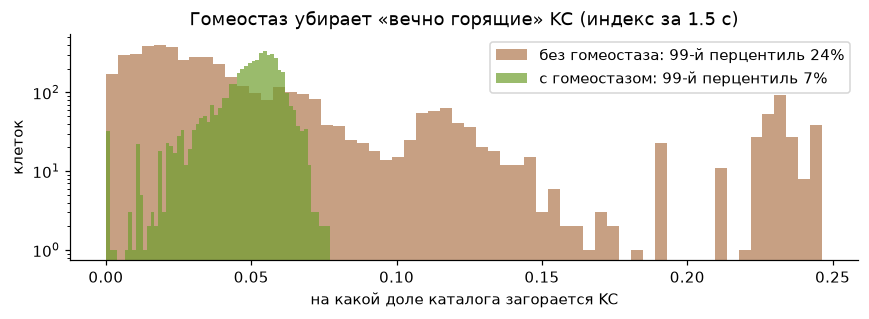

{'dead_kc_share': 0.006840530141085934, 'max_kc_activity': 0.07710704271812634, 'p99_kc_activity': 0.06828302820385948}


In [6]:
body = mushroom.flywire(c)
t = time.time(); idx = R.FlyIndex.build(body, enc, emb); build_s = time.time() - t
raw = mushroom.MushroomBody(body.W, 'без гомеостаза')
raw_codes = raw.codes(pn)
fig, ax = plt.subplots(figsize=(8, 3))
for codes, name, col in [(raw_codes, 'без гомеостаза', C['base']), (idx.codes, 'с гомеостазом', C['real'])]:
    share = np.bincount(codes.ravel(), minlength=body.n_kc) / len(codes)
    ax.hist(share, bins=60, alpha=.7, label=f'{name}: 99-й перцентиль {np.quantile(share, .99):.0%}', color=col)
ax.set(xlabel='на какой доле каталога загорается KC', ylabel='клеток', yscale='log', title=f'Гомеостаз убирает «вечно горящие» KC (индекс за {build_s:.1f} с)')
ax.legend(); plt.tight_layout(); plt.show()
print(R.kc_health(idx.codes, body.n_kc))

## 4. Муха ищет похожие товары

Похожесть для мухи — **сколько клеток Кеньона загорелось у двух товаров одновременно**. Индекс инвертированный:
для каждой KC хранится список товаров, где она активна. Ниже — три товара и их соседи по мнению мухи.

In [7]:
def neighbours(i, index, n=6):
    top, s = index.retrieve(index.codes[i], k=n + 1, exclude=[i])
    return [f'{sc:.0%} · {titles[j][:70]}' for j, sc in zip(top[:n], s[:n])]
for i in examples:
    print('▶', titles[i][:90]); print('\n'.join('   ' + x for x in neighbours(i, idx))); print()

▶ Проводная игровая мышь Logitech G102 LIGHTSYNC с кабелем, для компьютера и ноутбука, PC
   60% · Беспроводная компьютерная мышь W10
   59% · Проводная и беспроводная компьютерная мышь, RGB, для игр и работы
   59% · Белая беспроводная игровая мышь Mchose A7 V2 Pro+
   57% · Игровая мышь ATK Dragonfly A9 Plus беспроводная, ультралёгкая, оптичес
   55% · Игровая мышь ATK Dragonfly A9, беспроводная, легкая, оптическая, для П
   55% · Беспроводная мышь для компьютера, ноутбука, планшета, телефона, бесшум

▶ Лоток для кошек и собак, 38 x 28 x 6 см
   68% · Когтеточка для кошек: 26 см в длину, 20 см в ширину, толщина 3 см
   68% · Лоток для кошек и котят, с бортиком, 50.5x37.5x19.5 см
   62% · Двойная миска для кошек и собак, 25 * 19.5 * 6.5 см
   62% · Двойная миска для кошек и собак, 25 * 19.5 * 6.5 см
   62% · Лоток для кошек пластиковый с высокими бортиками для домашних животных
   62% · Лоток для кошек пластиковый с высокими бортиками для домашних животных

▶ Карандаш-помада для губ, 

### Сессии персон → полка

Сессия — это **смесь запахов** просмотренных товаров, как у мухи, когда пахнет сразу бананом и дрожжами.
Смесь проходит тот же путь и даёт один KC-код; товары ранжируются по общим KC. Персоны синтетические:
это 4 товара из каталога, подобранных по ключевым словам (`scripts/export_fly_index.py`).

In [8]:
model = json.loads((DATA / 'model.json').read_text())
pos = {p['id']: i for i, p in enumerate(catalog)}
mbon = mushroom.MBONValence(c['w_app'], c['w_avoid'])
table = {}
for p in model['personas']:
    s = [pos[i] for i in p['items']]
    shown, _ = R.mbon_rank(idx, mbon, idx.session_code(s), exclude=s, show=6, titles=titles)
    table[p['title']] = [titles[j][:55] for j in shown]
pd.DataFrame(table)

,Геймер в 3 часа ночи,Рыбак на выходных,Кошатница,Автолюбитель,Бьюти-блогерка,Студент перед сессией
0,Белая беспроводная игровая мышь Mchose A7 V2 Pro+,"Катушка рыболовная для рыбалки, спиннинга, фид...",Миска с поилкой для кошек и собак,"Очиститель карбюратора CARB, 450 мл","Кисточки для макияжа, в наборе 13 шт, с чехлом","Цветная бумага Star, А4, 16 листов, 8 цветов"
1,Комплект игровой клавиатуры и мыши с RGB-подсв...,"Поплавок щучий удлинённый для ловли на живца, ...","Шарик с кошачьей мятой на липучке, игрушка лиз...",Пленка тонировочная 100%,Кисточки для макияжа – набор кисточек 8 штук,"Блокнот А5 в линейку, 80 листов"
2,Беспроводная компьютерная мышь W10,Катушка фидерная KAIDA,Двойная миска для домашних животных,Очиститель карбюратора и дроссельной заслонки ...,"Набор для макияжа 8 март, набор косметики, Kik...","Бумага цветная, 16 цветов, 16 листов, А4 скреп..."
3,Проводная игровая мышь Logitech G102 LIGHTSYNC...,Катушка силовая сподовая карповая,"Лоток для кошек и собак, с высокими бортиками ...",Очиститель карбюратора VESLEE,Спреи для макияжа NYX,"Цветная бумага A4, ArtSpace, 16 листов, 16 цве..."
4,Механическая игровая клавиатура T-Wolf T80 с R...,Гранулированная приманка для рыбалки 25gr,"Кошачья мята для кошек, палочка мататаби натур...",Автошампунь-полироль с карнаубским воском LAVR...,"Набор косметики Dior, подарочный набор для жен...","Цветная бумага A4, ArtSpace ""Волшебная"", 10 ли..."
5,"Игровая клавиатура и мышь T-wolf TF200, TF270,...","Набор рыболовных кормушек, 4+1 прессформа 30,4...","Когтерез-секатор, для груминга кошек и собак м...",КАРБ - Очиститель карбюратора и дроссельной за...,"Спонж и апликаторы для макияжа, 20 штук в набо...","Тетрадь в клетку, 48 листов, жёлтая листовка, ..."


## 5. Настоящая ли от мухи польза? Контроли

Главный вопрос научной части: **даёт ли что-то именно измеренная проводка FlyWire**? Сравниваем на одном и том же входе:

- **Перемешанная проводка** — у каждой KC столько же входов, у каждой гломерулы столько же выходов, веса те же, но кто с кем соединён — случайно;
- **Случайный FlyHash** — входы KC из равномерно случайных гломерул (исходный алгоритм Dasgupta);
- **Раскладка «вразнобой»** — главные компоненты раздаются по гломерулам случайно (5 перестановок).

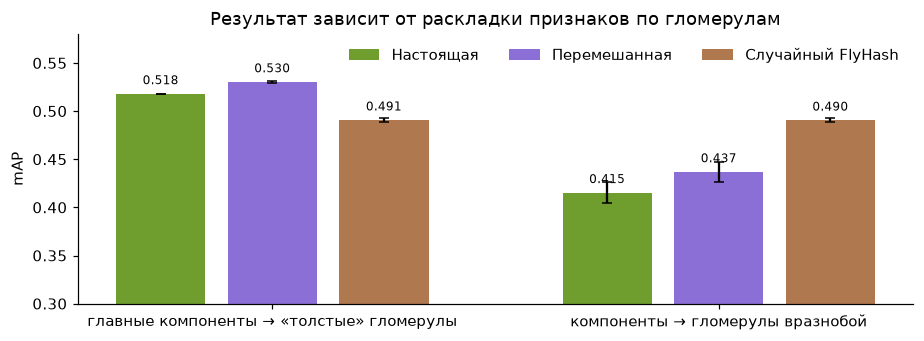

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 3.2))
variants = [('flywire', 'Настоящая', C['real']), ('shuffled', 'Перемешанная', C['fly']), ('random_flyhash', 'Случайный FlyHash', C['base'])]
for k, (v, name, col) in enumerate(variants):
    for j, m in enumerate(['по силе гломерулы', 'вразнобой']):
        vals = rows[(rows.variant == v) & (rows.mapping == m)]['map']
        ax.bar(j * 4 + k, vals.mean(), yerr=vals.std() if len(vals) > 1 else 0, color=col, capsize=3, label=name if j == 0 else None)
        ax.text(j * 4 + k, vals.mean() + .01, f'{vals.mean():.3f}', ha='center', fontsize=8)
ax.set_xticks([1, 5], ['главные компоненты → «толстые» гломерулы', 'компоненты → гломерулы вразнобой'])
ax.set(ylabel='mAP', ylim=(.3, .58), title='Результат зависит от раскладки признаков по гломерулам')
ax.legend(frameon=False, ncol=3, loc='upper right'); plt.tight_layout(); plt.show()

**Интерпретация.**

1. Когда главные признаки назначены наиболее связанным гломерулам, FlyWire даёт mAP 0,518, случайный FlyHash — 0,491, а контроль с сохранением степеней нейронов и весов каждой KC — 0,530. В этой прокси-задаче измеренный узор связей не дал преимущества.
2. При случайной раскладке признаков FlyWire снижается до среднего mAP 0,415. Следовательно, значимую часть результата определяет выбранное нами соответствие между текстовыми признаками и гломерулами.
3. Сравнение с 234-битным SimHash (mAP 0,427) не выравнивает бюджет памяти: KC-код содержит 4 678 позиций. Проверка при равной цене остаётся открытой.
4. Это согласуется с гипотезой о важности расширения и разреженности, но не доказывает продуктовую пользу. Метки соседей взяты из того же текстового эмбеддинга, который служит входом; на кликах и покупках опыт не проводился.


### Проверка из boltzmann-fly: доходит ли каждый вход до KC?

[boltzmann-fly](https://github.com/jniimi/boltzmann-fly) показал ловушку: при наивном назначении признаков только
20 из 72 доходили до KC. Проверяем: усиливаем одну гломерулу и смотрим, какая доля KC-кода меняется.

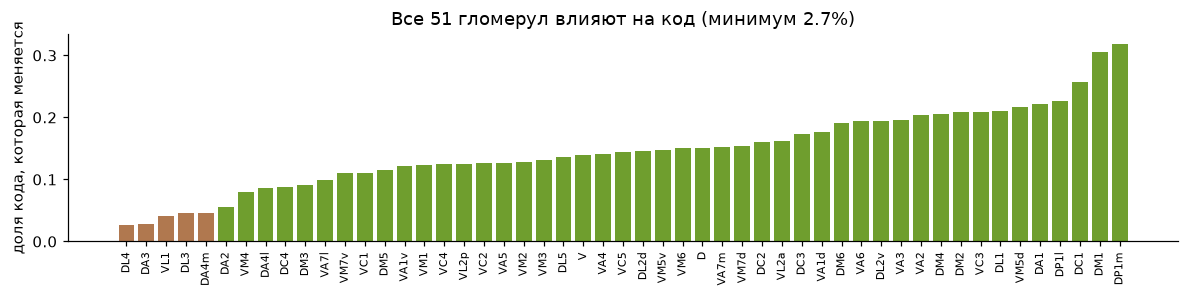

In [10]:
cov = pd.Series(ev['glomerulus_coverage']).sort_values()
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.bar(cov.index, cov.values, color=np.where(cov.values < .05, C['base'], C['real']))
ax.set(ylabel='доля кода, которая меняется', title=f'Все {len(cov)} гломерул влияют на код (минимум {cov.min():.1%})')
ax.tick_params(axis='x', rotation=90, labelsize=7); plt.tight_layout(); plt.show()

## 6. MBON и обратная связь: модель реагирует на лайки

Retrieval возвращает 200 кандидатов по числу общих KC. До обратной связи их порядок определяется только этим числом: исходная валентность MBON вычитается. Начальные веса KC → MBON взяты из FlyWire; холинергические и глутаматергические выходы грубо интерпретируются как «подойти» и «уйти» ([Aso et al., 2014](https://elifesciences.org/articles/04580)).

После лайка программа ослабляет веса активных KC на стороне избегания; после дизлайка — на стороне приближения. Это инженерное правило, вдохновлённое дофаминовой пластичностью, **не** симуляция DAN, PAM/PPL1 или компартментов. Итоговый score = доля общих KC + 2,5 × изменение валентности.

**Синтетический эксперимент.** Сессия геймера (мыши и клавиатуры). Пользователь на самом деле хочет **наушники**: лайкает наушники на полке и дизлайкает остальное. Сколько наушников на полке после каждого раунда?


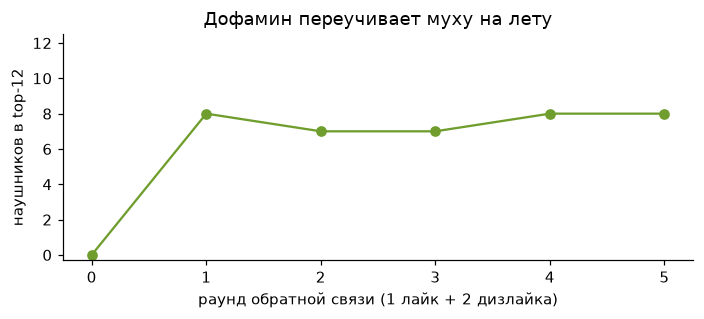

Полка после обучения:
  Наушники игровые беспроводные с микрофоном ONIKUMA
  Наушники игровые с микрофоном, проводные, с RGB подсветкой
  A2 Gaming Стерео Игровые Наушники с Микрофоном RGB LED для ПК, Ноутбука и Смартф
  Игровые наушники проводные 2E Gaming HG300 LED 2E-HG300BK, с микрофоном и подсве
  Игровые наушники с микрофоном G9000
  Remax RM-705 Gaming — проводные игровые наушники с микрофоном и RGB-подсветкой
  Проводные наушники игровые CANYON Shadder GH 6, С RGB подстветкой
  MORADI V10 USB7.1 проводные игровые наушники синий
  Игровая клавиатура Furycube с RGB подсветкой для геймеров (механическая / мембра
  Механическая клавиатура Компактная, RGB-подсветка
  Обучающий планшет с озвучкой рус-англ или узб-англ + 112 карточек в комплекте
  Механическая игровая клавиатура T-Wolf T80 с RGB-подсветкой


In [11]:
session = [pos[i] for i in model['personas'][0]['items']]
want = lambda j: 'наушник' in titles[j].lower()
code0 = idx.session_code(session)
likes, dislikes, curve = [], [], []
for rnd in range(6):
    shown, _ = R.mbon_rank(idx, mbon, code0, likes=likes, dislikes=dislikes, exclude=session, titles=titles)
    curve.append(sum(want(j) for j in shown))
    fresh_like = [j for j in shown if want(j) and j not in likes][:1]
    fresh_dis = [j for j in shown if not want(j) and j not in dislikes][:2]
    if not fresh_like:
        # на полке наушников нет: пользователь находит их поиском и лайкает (как «добавил в избранное»)
        cand, _ = idx.retrieve(code0, k=2000, exclude=session)
        fresh_like = [j for j in cand if want(j) and j not in likes][:1]
    likes += fresh_like; dislikes += fresh_dis
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(range(len(curve)), curve, marker='o', color=C['real'])
ax.set(xlabel='раунд обратной связи (1 лайк + 2 дизлайка)', ylabel='наушников в top-12', title='Дофамин переучивает муху на лету', ylim=(-.3, 12.5))
plt.tight_layout(); plt.show()
print('Полка после обучения:'); print('\n'.join('  ' + titles[j][:80] for j in R.mbon_rank(idx, mbon, code0, likes=likes, dislikes=dislikes, exclude=session, titles=titles)[0]))

Муха не видела ни одного реального пользователя. Всё «обучение» — это несколько синаптических
депрессий на 234 KC, которые загорались на лайкнутых товарах. Этого хватает, чтобы полка сменила тему.
Это **не** доказательство качества на реальном трафике. Это демонстрация механизма, который у мухи работает на запахах.

## 7. Спайки: весь мозг FlyWire в Brian2

Статический хэш — упрощение. Проверим, согласуется ли он с полной спайковой моделью мозга дрозофилы
[Shiu et al. (Nature, 2024)](https://www.nature.com/articles/s41586-024-07763-9): ~139 тыс. LIF-нейронов и 15 млн связей
FlyWire v783, вес = число синапсов × знак медиатора. Код авторов лежит в `vendor/drosophila_brain_model/` без изменений.
Мы только «даём понюхать»: ORN самых сильных гломерул запаха сессии получают Poisson-вход.

- Для геймера — кривая «доза–ответ»: от одной гломерулы на 20 Гц (**trace**) до 8 + 8 гломерул на 150/50 Гц (**strong**). Для остальных персон — **weak**: 3 гломерулы × 60 Гц + 3 × 20 Гц. 300 мс симуляции.
- Сравниваем top-234 спайкующих KC со статическим кодом и считаем долю активных PN/KC.

Прогон: `experiments/lif_validation.py`, около 5 минут на стимул на ноутбуке с M-процессором.

,title,intensity,strong_glomeruli,neurons_spiking,pn_active,kc_active,apl_hz,mbon_approach_hz,mbon_avoid_hz,spearman_homeostatic_drive,topk_overlap_with_static_code,topk_overlap_chance,совпадение / случайно
0,Геймер в 3 часа ночи,weak,"[DC1, DM4, VL2a]",8439,0.973,0.720,326.667,55.641,86.667,0.111,26,11.490,2.3
1,Геймер в 3 часа ночи,strong,"[DC1, DM3, DM4, VA7l, VC1, VL1, VL2a, VL2p]",9014,0.973,0.735,336.667,60.128,91.467,0.137,29,12.035,2.4
2,Геймер в 3 часа ночи,trace,[VL2a],8285,0.977,0.718,308.333,51.474,81.333,0.104,26,11.490,2.3
3,Геймер в 3 часа ночи,faint,[VL2a],8292,0.973,0.716,321.667,55.128,85.600,0.109,25,12.035,2.1
4,Рыбак на выходных,weak,"[DA4m, DP1l, VA1d]",8418,0.973,0.715,323.333,54.872,85.867,-0.041,18,11.925,1.5
5,Кошатница,weak,"[DP1l, VA7m, VM7d]",8431,0.969,0.719,323.333,55.449,86.267,-0.057,4,11.365,0.4
6,Автолюбитель,weak,"[DL2d, DM6, VA3]",8386,0.973,0.719,323.333,55.385,85.200,0.051,11,11.380,1.0
7,Бьюти-блогерка,weak,"[DC4, DL1, VM1]",8399,0.977,0.718,325.000,55.192,86.267,0.024,15,11.510,1.3
8,Студент перед сессией,weak,"[DM3, V, VL1]",8545,0.977,0.713,318.333,53.590,84.133,0.023,9,12.210,0.7


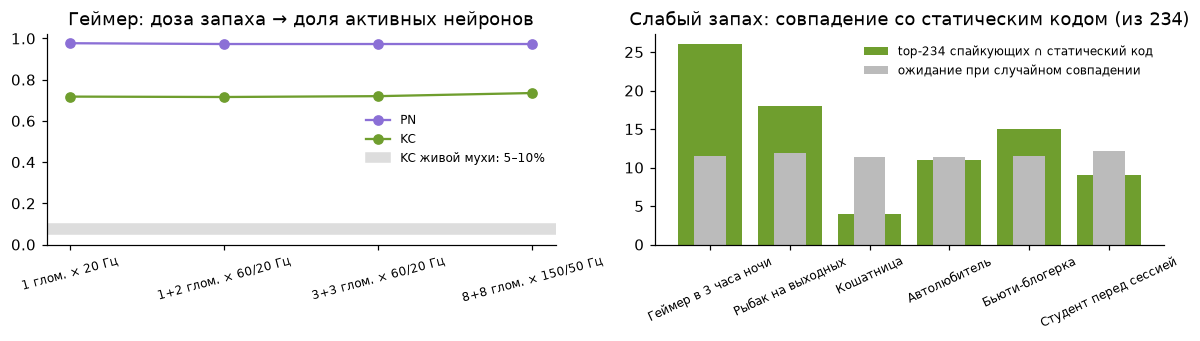

In [12]:
lif_path = DATA / 'lif_results.json'
if lif_path.exists():
    lif = pd.DataFrame(json.loads(lif_path.read_text())['stimuli']).drop(columns=['map_spikes_sparse'])
    lif['совпадение / случайно'] = (lif.topk_overlap_with_static_code / lif.topk_overlap_chance).round(1)
    show = lif[['title', 'intensity', 'strong_glomeruli', 'neurons_spiking', 'pn_active', 'kc_active', 'apl_hz', 'mbon_approach_hz', 'mbon_avoid_hz', 'spearman_homeostatic_drive', 'topk_overlap_with_static_code', 'topk_overlap_chance', 'совпадение / случайно']]
    display(show.round(3))
    levels = ['trace', 'faint', 'weak', 'strong']
    lvl_name = {'trace': '1 глом. × 20 Гц', 'faint': '1+2 глом. × 60/20 Гц', 'weak': '3+3 глом. × 60/20 Гц', 'strong': '8+8 глом. × 150/50 Гц'}
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
    g = lif[lif.persona == 'gamer'].set_index('intensity').reindex([l for l in levels if l in set(lif.intensity)])
    x = range(len(g))
    axs[0].plot(x, g.pn_active, marker='o', color=C['fly'], label='PN')
    axs[0].plot(x, g.kc_active, marker='o', color=C['real'], label='KC')
    axs[0].axhspan(.05, .10, color='#ddd', label='KC живой мухи: 5–10%')
    axs[0].set_xticks(list(x), [lvl_name[l] for l in g.index], rotation=15, fontsize=8)
    axs[0].set(title='Геймер: доза запаха → доля активных нейронов', ylim=(0, 1.02)); axs[0].legend(frameon=False, fontsize=8)
    w = lif[lif.intensity == 'weak']
    axs[1].bar(w.title, w.topk_overlap_with_static_code, color=C['real'], label='top-234 спайкующих ∩ статический код')
    axs[1].bar(w.title, w.topk_overlap_chance, color='#bbb', width=.4, label='ожидание при случайном совпадении')
    axs[1].set(title='Слабый запах: совпадение со статическим кодом (из 234)'); axs[1].legend(frameon=False, fontsize=8)
    axs[1].tick_params(axis='x', rotation=25, labelsize=8)
    plt.tight_layout(); plt.show()
else:
    print('Сначала запустите experiments/lif_validation.py')

**Что это значит.**

- При испытанных стимулах полная LIF-модель Shiu et al. даёт около 70% активных KC даже для слабого запаха. Эта настройка не воспроизводит разреженный код грибовидного тела. Без опыта без стимула и абляции рекуррентных связей причину высокой активности установить нельзя.
- Top-234 спайкующих KC совпадают со статическим кодом примерно на уровне случайного ожидания: около 14 против 12. Это разные модели и разные режимы активности; из этого опыта нельзя вывести качество retrieval.
- Товары на сайте выбирает статический контур. Для исходных персон FlyWire после сборки полки карта может показывать заранее рассчитанную запись Brian2. LN/APL/DAN в обычной карте представлены условными индикаторами, а не рассчитанными спайками.


## 8. Что дальше

1. **Реальные сессии.** дополнительная офлайн-проверка на согласованных реальных сессиях после определения схемы и разрешения на данные.
   Recall@12/@200 следующего действия для настоящей, перемешанной и случайной мухи, плотного косинуса и популярности.
   Нужен доступ к Trino/ClickHouse: на момент подготовки внутренний контур был недоступен, поэтому скрипт **не запускался**.
2. **Эмбеддинги RecSys вместо текстовых.** Подать на вход мухи вектора UzumFormer/NeuralV2 (обучаемый адаптер в 51 гломерулу)
   и повторить контроли. Правило то же: если настоящая проводка не лучше перемешанной, биологическую гипотезу не принимаем.
3. **Shadow-стрим.** Контракт `retrieve(context, k) → [product_id, fly_score]` уже реализован в `lib/fly.mjs` и `flyrec.retrieval`.
   Индекс 24 тыс. товаров строится за ~1 с, запрос ~10–20 мс на CPU; на полный каталог нужен замер памяти и p99.

## Источники и лицензии

- FlyWire v783: Dorkenwald et al., *Nature* 2024; Schlegel et al., *Nature* 2024 (разметка типов клеток). Данные CC BY 4.0.
- Связность и LIF-модель: Shiu et al., *Nature* 2024 — [philshiu/Drosophila_brain_model](https://github.com/philshiu/Drosophila_brain_model) (MIT).
- FlyHash: Dasgupta, Stevens, Navlakha, *Science* 2017.
- Нормализация в антеннальной доле: Olsen, Bhandawat, Wilson, *Neuron* 2010. Гомеостаз KC: Apostolopoulou & Lin, 2020.
- MBON и дофамин: Aso et al., *eLife* 2014; Hige et al., *Neuron* 2015.
- Идеи контролей: [awesome-fly](https://github.com/cobanov/awesome-fly), [boltzmann-fly](https://github.com/jniimi/boltzmann-fly).
- Каталог — исторический срез публичных полей товаров Uzum Market (ID, название, категория), июль 2026.